# 4.6 ความครอบคลุมของข้อมูล การกระจุกตัวเชิงพื้นที่ และความน่าเชื่อถือของตัวชี้วัด

ส่วนเสริมตามแผนพัฒนาระยะถัดไป (§6.1, §7.3) ใช้ข้อมูลที่มีอยู่แล้วเท่านั้น

| ส่วน | คำถาม |
|---|---|
| A | ข้อมูลกำลังคนครอบคลุมจังหวัด ปี วิชาชีพ และสังกัดใดบ้าง ค่าว่างกับค่าศูนย์ต่างกันตรงไหน |
| B | แพทย์เฉพาะทางกระจุกอยู่ในสถานพยาบาลใด และการกระจุกเปลี่ยนไปอย่างไร (ข้อมูลรายสถานพยาบาล spc) |
| C | จังหวัดใดที่อันดับตามประชากร บริการ ความจำเป็น M5 และภาระโรคให้ข้อสรุปต่างกัน และคำอธิบายที่น่าจะเป็น |
| D | สรุปความน่าเชื่อถือของตัวชี้วัดในบทที่ 4 (ข้ามจังหวัด ข้ามเวลา ภาระโรค) |

ข้อมูลรายสถานพยาบาล (`data/spc_aggregated.csv`) เป็นจำนวนตามแบบรายงานของสถานพยาบาล ไม่ใช่จำนวนคนที่ไม่ซ้ำ หมวด "Physician" คือยอดรวมแพทย์ทั้งสถานพยาบาล อีก 17 หมวดเป็นสาขาย่อย จึงไม่รวมทั้ง 18 หมวด ความครอบคลุมเปลี่ยนในปี 2559 และยอดผิดปกติในปี 2563 ช่วงหลักจึงใช้ 2560–2567 ไม่รวม 2563 ผลทั้งหมดเป็นเชิงพรรณนา ไม่ใช่ผลเชิงเหตุผล

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "analysis.toml").exists())
sys.path.insert(0, str(_root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display

from chapter4 import config as C, panels as P, metrics as M, reporting as R
from chapter4.ingest import load

pd.options.display.max_columns = 40
pd.options.display.width = 200
FONT = R.setup_style()
S = R.Section("4_6")
Y0, Y1 = C.Y0, C.Y1
EN = C.CADRE_EN
BK = int(P.key().query("is_bangkok").prov_code.iloc[0])
KEY = P.key().set_index("prov_code")
NAME = KEY.province.to_dict()
SPC_YEARS = [y for y in range(2017, 2025) if y != 2020]
T43 = C.OUTPUTS / "chapter4_3" / "tables"
T45 = C.OUTPUTS / "chapter4_5" / "tables"
for f in [T43 / "T43_PRIORITY_RANKS.csv", T45 / "T45_PRIORITY_BURDEN.csv"]:
    if not f.exists():
        raise FileNotFoundError(f"{f.name} missing - run sections 4.3 and 4.5 first")

---
# ส่วน A — ความครอบคลุมของข้อมูลกำลังคน
ตารางจังหวัด × ปี × วิชาชีพ × สังกัด จากรายงานทรัพยากรสาธารณสุข แยก **ไม่รายงาน (ค่าว่าง)** ออกจาก **รายงานศูนย์คน** และระบุปีที่ยอดรวมประเทศเปลี่ยนเกินร้อยละ 25

In [2]:
w = P.workforce_long(raw=True)
w = w[w.sector != "published_total"]
cov = (w.assign(state=np.where(w.headcount.isna(), "missing", np.where(w.headcount == 0, "zero", "positive")))
       .groupby(["cadre", "sector", "year", "state"]).prov_code.nunique().unstack("state", fill_value=0).reset_index())
for c in ["missing", "zero", "positive"]:
    if c not in cov:
        cov[c] = 0
nat = w.groupby(["cadre", "sector", "year"]).headcount.sum(min_count=1).rename("national_total").reset_index()
cov = cov.merge(nat, on=["cadre", "sector", "year"])
cov["yoy_change_pct"] = cov.groupby(["cadre", "sector"]).national_total.pct_change() * 100
cov["break_flag"] = cov.yoy_change_pct.abs() > 25
cov["cadre_en"] = cov.cadre.map(EN)
S.table("T46_COVERAGE_MATRIX", cov, "ความครอบคลุมของข้อมูลกำลังคน: จำนวนจังหวัดที่ไม่รายงาน รายงานศูนย์ และรายงานค่าบวก รายวิชาชีพ × สังกัด × ปี พร้อมปีที่ยอดรวมเปลี่ยนเกินร้อยละ 25", main=True)
brk = cov[cov.break_flag & cov.year.gt(Y0)][["cadre", "sector", "year", "yoy_change_pct", "national_total"]]
S.table("T46_COVERAGE_BREAKS", brk, "ปีที่ยอดรวมระดับประเทศเปลี่ยนเกินร้อยละ 25 (จุดที่ต้องตรวจนิยามหรือความครอบคลุม)")
display(brk.round(1))
S.claim("c46_cov_cells", len(w), "int", "จังหวัด-ปี-วิชาชีพ-สังกัด")
S.claim("c46_cov_missing", int(w.headcount.isna().sum()), "int", "ช่อง")
S.claim("c46_cov_zero", int((w.headcount == 0).sum()), "int", "ช่อง")
S.claim("c46_cov_breaks", len(brk), "int", "จุด")
SECTOR_TH = {"moph": "สธ.", "other_public": "รัฐอื่น", "private": "เอกชน", "unclassified": "ไม่จำแนก"}
S.claim("c46_cov_breaks_moph", int((brk.sector == "moph").sum()), "int", "จุด")
S.claim("c46_cov_breaks_private", int((brk.sector == "private").sum()), "int", "จุด")
defs = pd.DataFrame([
    dict(universe="all_sectors", definition="ทุกสังกัด (สธ. หน่วยงานรัฐอื่น เอกชน ไม่จำแนก) ตามรายงานทรัพยากรสาธารณสุข", unit="headcount", note="ไม่ใช่ FTE; ไม่ทราบการทำงานหลายแห่ง"),
    dict(universe="moph", definition="สังกัดกระทรวงสาธารณสุข (กว้างกว่า สป.สธ.)", unit="headcount", note="บทที่ 5 ใช้เป็นตัวแทนชั่วคราวของ สป.สธ."),
    dict(universe="ops (HROPS events)", definition="เหตุการณ์รับเข้า/ออกของ สป.สธ.", unit="events", note="ขอบเขตแคบกว่าจำนวนคงอยู่; เหตุการณ์ไม่ใช่จำนวนคน"),
    dict(universe="facility returns (spc/hrh)", definition="แบบรายงานรายสถานพยาบาล (GIS Health)", unit="positions in returns", note="นับซ้ำได้เมื่อทำงานหลายแห่ง; ความครอบคลุมเปลี่ยนปี 2559 และผิดปกติปี 2563"),
    dict(universe="active practice / FTE", definition="แพทย์ที่ปฏิบัติงานจริงและเวลาทำงาน", unit="FTE", note="ไม่มีในโครงการ — ต้องขอข้อมูล"),
])
S.table("T46_UNIVERSE_DEFINITIONS", defs, "นิยามขอบเขตกำลังคนที่ใช้ในโครงการ และสิ่งที่แต่ละขอบเขตไม่ได้วัด")

,cadre,sector,year,yoy_change_pct,national_total
17,ทันตแพทย์,other_public,2017,28.4,1919.0
18,ทันตแพทย์,other_public,2018,-26.0,1420.0
27,ทันตแพทย์,private,2014,-73.9,462.0
30,ทันตแพทย์,private,2017,437.7,2124.0
31,ทันตแพทย์,private,2018,-80.5,414.0
40,ทันตแพทย์,unclassified,2017,-100.0,0.0
82,พยาบาลวิชาชีพ,unclassified,2017,-100.0,0.0
85,พยาบาลเทคนิค,moph,2014,68.1,4498.0
86,พยาบาลเทคนิค,moph,2015,-51.6,2177.0
88,พยาบาลเทคนิค,moph,2017,-26.6,1539.0


,universe,definition,unit,note
0,all_sectors,ทุกสังกัด (สธ. หน่วยงานรัฐอื่น เอกชน ไม่จำแนก)...,headcount,ไม่ใช่ FTE; ไม่ทราบการทำงานหลายแห่ง
1,moph,สังกัดกระทรวงสาธารณสุข (กว้างกว่า สป.สธ.),headcount,บทที่ 5 ใช้เป็นตัวแทนชั่วคราวของ สป.สธ.
2,ops (HROPS events),เหตุการณ์รับเข้า/ออกของ สป.สธ.,events,ขอบเขตแคบกว่าจำนวนคงอยู่; เหตุการณ์ไม่ใช่จำนวนคน
3,facility returns (spc/hrh),แบบรายงานรายสถานพยาบาล (GIS Health),positions in returns,นับซ้ำได้เมื่อทำงานหลายแห่ง; ความครอบคลุมเปลี่...
4,active practice / FTE,แพทย์ที่ปฏิบัติงานจริงและเวลาทำงาน,FTE,ไม่มีในโครงการ — ต้องขอข้อมูล


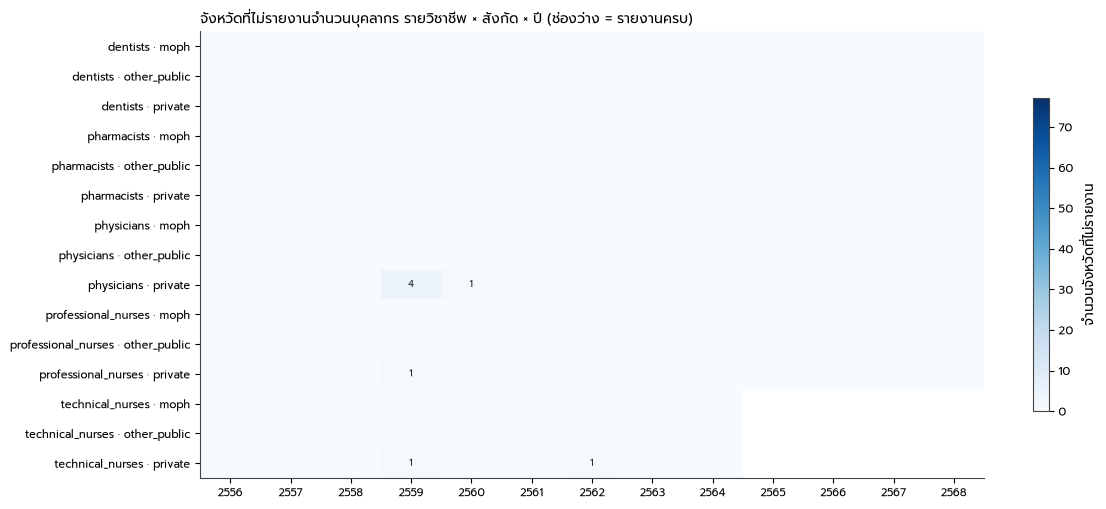

In [3]:
piv = cov[cov.sector.isin(["moph", "other_public", "private"])].assign(
    row=lambda d: d.cadre_en.fillna(d.cadre) + " · " + d.sector).pivot_table(index="row", columns="year", values="missing")
fig, ax = plt.subplots(figsize=(12, 5.2))
im = ax.imshow(piv.to_numpy(float), cmap="Blues", aspect="auto", vmin=0, vmax=77)
ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index, fontsize=8)
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels([C.be(y) for y in piv.columns], fontsize=8)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.iloc[i, j]
        if v > 0:
            ax.text(j, i, f"{int(v)}", ha="center", va="center", fontsize=7, color="white" if v > 40 else "#222")
fig.colorbar(im, ax=ax, shrink=0.7, label="จำนวนจังหวัดที่ไม่รายงาน")
ax.set_title("จังหวัดที่ไม่รายงานจำนวนบุคลากร รายวิชาชีพ × สังกัด × ปี (ช่องว่าง = รายงานครบ)", fontsize=10, loc="left")
fig.tight_layout()
S.figure("F46_COVERAGE", fig, piv.reset_index(), "ความครอบคลุมของข้อมูลกำลังคนรายวิชาชีพและสังกัด: จำนวนจังหวัดที่ไม่รายงานในแต่ละปี", main=True)
plt.show()

---
# ส่วน B — การกระจุกตัวของแพทย์เฉพาะทางระหว่างสถานพยาบาล
จับคู่รายงานรายสถานพยาบาลกับทะเบียนสถานพยาบาล (`data/hosp.csv` รหัส 5 หลัก) เพื่อระบุจังหวัด สังกัด และระดับ
แล้วเทียบยอด "Physician" รายจังหวัดกับรายงานทรัพยากรสาธารณสุข (ทุกสังกัด) เพื่อเลือกปีที่เชื่อถือได้

In [4]:
spc = pd.read_csv(C.ROOT / "data/spc_aggregated.csv").drop(columns=["Unnamed: 0"], errors="ignore")
hosp = pd.read_csv(C.ROOT / "data/hosp.csv", low_memory=False, dtype=str)
clean = lambda v: pd.to_numeric(v.astype(str).str.replace('="', "", regex=False).str.replace('"', "", regex=False), errors="coerce")
hosp["hosp_id"] = clean(hosp["รหัส 5 หลัก"])
hosp["prov_code"] = clean(hosp["รหัสจังหวัด"])
TYPE = {"โรงพยาบาลศูนย์": "regional_general", "โรงพยาบาลทั่วไป": "regional_general", "โรงพยาบาลชุมชน": "community",
        "โรงพยาบาลเอกชน": "private"}
hosp["tier"] = hosp["ประเภทหน่วยบริการสุขภาพ"].map(TYPE).fillna("other_public")
fac = hosp.dropna(subset=["hosp_id"]).drop_duplicates("hosp_id").set_index("hosp_id")[["prov_code", "tier", "สังกัด", "ระดับโรงพยาบาล"]]
sp = spc.join(fac, on="hosp_id")
match = float(sp.drop_duplicates("hosp_id").prov_code.notna().mean())
S.claim("c46_spc_match", 100 * match, "{:.1f}", "%")
assert match > 0.99, "facility registry join failed"
TIER_TH = {"regional_general": "รพ.ศูนย์/ทั่วไป", "community": "รพ.ชุมชน", "private": "รพ.เอกชน", "other_public": "รพ.รัฐนอก สธ./อื่น"}
SPECIALTIES = sorted(set(spc.spc) - {"Physician", "General Practitioner"})
# reconciliation of the facility total with the HRR all-sector stock
hrr = P.workforce_province("all_sectors", ["แพทย์"]).rename(columns={"headcount": "hrr_all"})[["year", "prov_code", "hrr_all"]]
rec = (sp[sp.spc == "Physician"].groupby(["year", "prov_code"]).total.sum().rename("spc_physician").reset_index()
       .merge(hrr, on=["year", "prov_code"], how="left"))
rec["ratio"] = rec.spc_physician / rec.hrr_all
rs = rec.groupby("year").agg(facilities=("prov_code", "size"), ratio_median=("ratio", "median"),
                             ratio_p10=("ratio", lambda s: s.quantile(.1)), ratio_p90=("ratio", lambda s: s.quantile(.9)),
                             spc_total=("spc_physician", "sum"), hrr_total=("hrr_all", "sum")).reset_index()
rs["in_main_window"] = rs.year.isin(SPC_YEARS)
S.table("T46_SPC_RECONCILIATION", rs, "ยอดแพทย์จากรายงานรายสถานพยาบาลเทียบรายงานทรัพยากรสาธารณสุข (ทุกสังกัด) รายจังหวัด: มัธยฐานและช่วง P10–P90 ของอัตราส่วน")
display(rs.round(3))
for r in rs.itertuples():
    S.claim(f"c46_spc_ratio_{r.year}", r.ratio_median, "{:.2f}", "")
S.text_claim("c46_spc_window", f"{C.be(SPC_YEARS[0])}–{C.be(SPC_YEARS[-1])} ไม่รวม {C.be(2020)}")

,year,facilities,ratio_median,ratio_p10,ratio_p90,spc_total,hrr_total,in_main_window
0,2015,77,0.734,0.317,1.238,22868.0,31819.0,False
1,2016,77,1.098,0.793,1.766,34305.0,31275.0,False
2,2017,77,0.874,0.738,1.400,34099.0,35314.0,True
3,2018,77,1.101,0.858,1.697,41175.0,36807.0,True
4,2019,77,0.766,0.643,0.905,35067.0,38988.0,True
5,2020,77,1.557,1.134,1.990,52621.0,36270.0,False
6,2021,77,0.942,0.843,1.120,39764.0,38698.0,True
7,2022,77,0.970,0.880,1.075,41573.0,39005.0,True
8,2023,77,0.959,0.881,1.044,43006.0,42251.0,True
9,2024,77,0.990,0.904,1.111,46854.0,43587.0,True


In [5]:
spec = sp[sp.spc.isin(SPECIALTIES) & sp.year.isin(SPC_YEARS)]
rows = []
for scope, z in [("all", spec), ("moph", spec[spec["สังกัด"] == "กระทรวงสาธารณสุข"])]:
    for y, g in z.groupby("year"):
        f = g.groupby("hosp_id").total.sum()
        f = f[f > 0]
        srt = np.sort(f.to_numpy())[::-1]
        top = srt[: max(1, int(np.ceil(0.10 * len(srt))))].sum() / srt.sum()
        tier = g.groupby("tier").total.sum() / g.total.sum()
        rows.append(dict(scope=scope, year=y, specialists=float(f.sum()), facilities_with_specialists=len(f),
                         gini_across_facilities=M.weighted_gini(f.to_numpy(), np.ones(len(f))), top10pct_share=top,
                         **{f"share_{k}": float(tier.get(k, 0.0)) for k in TIER_TH}))
CONC = pd.DataFrame(rows)
S.table("T46_SPECIALIST_CONCENTRATION", CONC, "การกระจุกตัวของแพทย์เฉพาะทาง (16 สาขา ไม่รวมแพทย์ทั่วไป) ระหว่างสถานพยาบาล: Gini, สัดส่วนของ 10% สถานพยาบาลที่มีมากที่สุด และสัดส่วนตามระดับสถานพยาบาล", main=True)
display(CONC.round(3))
a0, a1 = CONC[(CONC.scope == "all") & (CONC.year == SPC_YEARS[0])].iloc[0], CONC[(CONC.scope == "all") & (CONC.year == SPC_YEARS[-1])].iloc[0]
m0, m1 = CONC[(CONC.scope == "moph") & (CONC.year == SPC_YEARS[0])].iloc[0], CONC[(CONC.scope == "moph") & (CONC.year == SPC_YEARS[-1])].iloc[0]
for tag, r in [("all0", a0), ("all1", a1), ("moph0", m0), ("moph1", m1)]:
    S.claim(f"c46_conc_gini_{tag}", r.gini_across_facilities, "{:.3f}", "")
    S.claim(f"c46_conc_top10_{tag}", 100 * r.top10pct_share, "{:.1f}", "%")
    S.claim(f"c46_conc_rg_{tag}", 100 * r.share_regional_general, "{:.1f}", "%")
    S.claim(f"c46_conc_ch_{tag}", 100 * r.share_community, "{:.1f}", "%")
    S.claim(f"c46_conc_pv_{tag}", 100 * r.share_private, "{:.1f}", "%")
    S.claim(f"c46_conc_n_{tag}", r.specialists, "int", "ตำแหน่ง")
# within MOPH: community-hospital specialists vs regional/general growth by province (descriptive co-movement)
mo = spec[spec["สังกัด"] == "กระทรวงสาธารณสุข"].groupby(["prov_code", "tier", "year"]).total.sum().unstack("year")
y0, y1 = SPC_YEARS[0], SPC_YEARS[-1]
ch = mo.xs("community", level="tier")[[y0, y1]] if "community" in mo.index.get_level_values(1) else None
rg = mo.xs("regional_general", level="tier")[[y0, y1]]
allphys = sp[(sp.spc == "Physician") & (sp["สังกัด"] == "กระทรวงสาธารณสุข") & (sp.tier == "community") & sp.year.isin([y0, y1])] \
    .groupby(["prov_code", "year"]).total.sum().unstack("year")
CM = pd.DataFrame({"rg_specialists_change_pct": 100 * (rg[y1] / rg[y0] - 1), "ch_specialists_y0": ch[y0], "ch_specialists_y1": ch[y1],
                   "ch_physicians_change_pct": 100 * (allphys[y1] / allphys[y0] - 1)}).dropna()
CM = CM[np.isfinite(CM).all(axis=1)]
CM = CM.assign(province=CM.index.map(NAME)).reset_index()
rho = spearmanr(CM.rg_specialists_change_pct, CM.ch_physicians_change_pct)
S.table("T46_CENTRE_COMMUNITY_COMOVEMENT", CM, f"การเปลี่ยนแปลงแพทย์เฉพาะทางใน รพ.ศูนย์/ทั่วไป กับแพทย์ใน รพ.ชุมชนของจังหวัดเดียวกัน (สังกัด สธ., {C.be(y0)}–{C.be(y1)}) — ความสัมพันธ์เชิงพรรณนา")
S.claim("c46_comove_rho", rho.statistic, "{:+.2f}", "")
S.claim("c46_comove_p", rho.pvalue, "{:.2f}", "")
S.claim("c46_comove_n", len(CM), "int", "จังหวัด")
S.claim("c46_ch_spec_share_provinces_none_y1", int((CM.ch_specialists_y1 == 0).sum()), "int", "จังหวัด")
print(rho)

,scope,year,specialists,facilities_with_specialists,gini_across_facilities,top10pct_share,share_regional_general,share_community,share_private,share_other_public
0,all,2017,23398.0,918,0.757,0.636,0.358,0.062,0.248,0.332
1,all,2018,24315.0,958,0.748,0.624,0.339,0.064,0.252,0.345
2,all,2019,28572.0,1034,0.756,0.641,0.333,0.069,0.253,0.346
3,all,2021,29931.0,1115,0.742,0.616,0.336,0.072,0.281,0.311
4,all,2022,34023.0,1152,0.759,0.642,0.332,0.071,0.258,0.339
5,all,2023,32521.0,1186,0.742,0.610,0.361,0.078,0.263,0.297
6,all,2024,35980.0,1219,0.754,0.635,0.323,0.080,0.255,0.343
7,moph,2017,10956.0,590,0.753,0.636,0.765,0.132,0.000,0.103
8,moph,2018,11033.0,611,0.741,0.617,0.747,0.141,0.000,0.112
9,moph,2019,13077.0,650,0.751,0.630,0.727,0.150,0.000,0.122


SignificanceResult(statistic=np.float64(0.3082547404969126), pvalue=np.float64(0.007132705298979796))


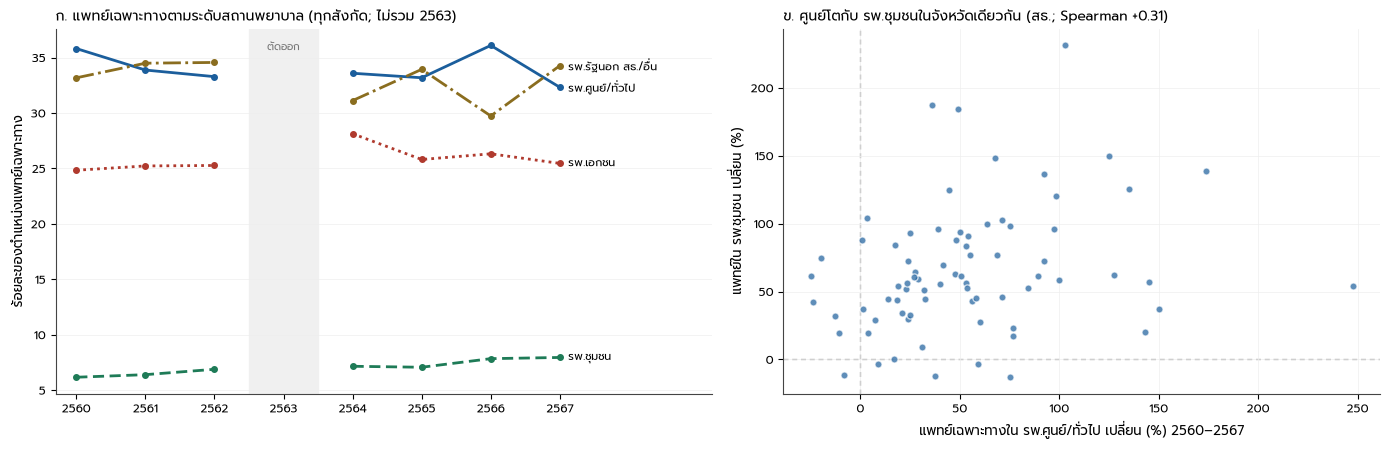

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1.1, 1]))
ax = axes[0]
z = CONC[CONC.scope == "all"].set_index("year").reindex(range(SPC_YEARS[0], SPC_YEARS[-1] + 1))   # 2020 left as a gap
styles = {"regional_general": ("#1b5e9c", "-"), "community": ("#1e7b57", (0, (4, 2))), "private": ("#b03a2e", (0, (1, 1.5))),
          "other_public": ("#8a6d1f", "-.")}
for k, (col, ls) in styles.items():
    ax.plot(z.index, 100 * z[f"share_{k}"], color=col, ls=ls, lw=2, marker="o", ms=4)
    ax.annotate(TIER_TH[k], (z.index[-1], 100 * z[f"share_{k}"].iloc[-1]), xytext=(6, 0), textcoords="offset points", fontsize=8, va="center")
R.be_ticks(ax, list(range(SPC_YEARS[0], SPC_YEARS[-1] + 1)), step=1)
ax.axvspan(2019.5, 2020.5, color="#f0f0f0", zorder=0)
ax.text(2020, ax.get_ylim()[1] * 0.97, "ตัดออก", ha="center", va="top", fontsize=7.5, color="#777")
ax.set_xlim(SPC_YEARS[0] - 0.3, SPC_YEARS[-1] + 2.2)
ax.set_ylabel("ร้อยละของตำแหน่งแพทย์เฉพาะทาง")
ax.set_title(f"ก. แพทย์เฉพาะทางตามระดับสถานพยาบาล (ทุกสังกัด; ไม่รวม {C.be(2020)})", fontsize=10, loc="left")
ax.grid(axis="y", color="#eeeeee", linewidth=0.5)
ax = axes[1]
ax.scatter(CM.rg_specialists_change_pct, CM.ch_physicians_change_pct, s=26, color="#1b5e9c", alpha=0.7, edgecolor="white", zorder=3)
ax.axhline(0, **R.REFLINE_KW); ax.axvline(0, **R.REFLINE_KW)
ax.set_xlabel(f"แพทย์เฉพาะทางใน รพ.ศูนย์/ทั่วไป เปลี่ยน (%) {C.be(y0)}–{C.be(y1)}")
ax.set_ylabel("แพทย์ใน รพ.ชุมชน เปลี่ยน (%)")
ax.set_title(f"ข. ศูนย์โตกับ รพ.ชุมชนในจังหวัดเดียวกัน (สธ.; Spearman {rho.statistic:+.2f})", fontsize=10, loc="left")
ax.grid(color="#eeeeee", linewidth=0.5, zorder=0)
fig.tight_layout()
S.figure("F46_SPECIALIST_CONCENTRATION", fig, CONC, "การกระจุกตัวของแพทย์เฉพาะทางตามระดับสถานพยาบาล และการเปลี่ยนแปลงของ รพ.ชุมชนในจังหวัดที่ รพ.ศูนย์/ทั่วไปโตต่างกัน (เชิงพรรณนา)", main=True)
plt.show()

---
# ส่วน C — อันดับจังหวัดตามตัวหารต่างชนิด: ตรงกันหรือขัดกันที่ใด
แพทย์ สธ. ปี 2568: 19 จังหวัดต่ำสุดตามประชากร (P), ครั้งผู้ป่วยนอก (S), ความจำเป็นอ้างอิง M5 (N) และ DALY คาดหมาย (B)
จัดกลุ่มความขัดกัน แล้วแสดงตัวบ่งชี้ที่อาจอธิบาย: มี รพ.ศูนย์หรือไม่ (บทบาทรับส่งต่อ), สัดส่วนแพทย์นอก สธ., ปริมณฑลกรุงเทพฯ, อายุ

In [7]:
pr = pd.read_csv(T43 / "T43_PRIORITY_RANKS.csv", encoding="utf-8-sig")
pb = pd.read_csv(T45 / "T45_PRIORITY_BURDEN.csv", encoding="utf-8-sig")
rk = pd.concat([pr[(pr.cadre == "แพทย์") & (pr.scope == "moph") & pr.denominator.isin(["population", "op_visits", "m5_op_moph"])],
                pb[(pb.cadre == "แพทย์") & (pb.scope == "moph") & (pb.denominator == "bod_count")]])
pv = rk.pivot_table(index="prov_code", columns="denominator", values="priority", aggfunc="first").astype(bool)
pv.columns = [{"population": "P", "op_visits": "S", "m5_op_moph": "N", "bod_count": "B"}[c] for c in pv.columns]
rkv = rk.pivot_table(index="prov_code", columns="denominator", values="rank", aggfunc="first")
rkv.columns = [{"population": "P", "op_visits": "S", "m5_op_moph": "N", "bod_count": "B"}[c] for c in rkv.columns]
def group(r):
    n = r[["P", "S", "N", "B"]].sum()
    if n == 4: return "all_four"
    if n == 0: return "none"
    if r.B and not r.S: return "need_not_service"
    if r.S and not r.B: return "service_not_need"
    return "mixed"
G = pv.assign(group=pv.apply(group, axis=1))
rgc = hosp[(hosp["ประเภทหน่วยบริการสุขภาพ"] == "โรงพยาบาลศูนย์")].groupby("prov_code").size()
pan = P.province_panel()[0]
p25 = pan[pan.year == Y1].set_index("prov_code")
G = G.join(rkv.add_prefix("rank_"))
G["has_regional_hospital"] = G.index.map(lambda p: int(rgc.get(p, 0)) > 0)
G["non_moph_physician_share"] = 1 - p25.moph_physicians / p25.all_sectors_physicians
G["share_60plus"] = p25["s3_60+"]
G["op_visits_per_person"] = p25.op_moph_pc
G["bangkok_vicinity"] = G.index.isin([11, 12, 13, 73, 74])
G["province"] = G.index.map(NAME)
G = G.reset_index()
S.table("T46_RANK_DISAGREEMENT", G, "19 จังหวัดต่ำสุดตามตัวหาร P, S, N, B (แพทย์ สธ. 2568) กลุ่มความขัดกัน และตัวบ่งชี้ที่อาจอธิบาย", main=True)
summ = G.groupby("group").agg(provinces=("prov_code", "size"), has_regional_hospital=("has_regional_hospital", "mean"),
                              non_moph_share=("non_moph_physician_share", "median"), op_per_person=("op_visits_per_person", "median"),
                              share_60plus=("share_60plus", "median"), bangkok_vicinity=("bangkok_vicinity", "sum")).reset_index()
S.table("T46_RANK_DISAGREEMENT_SUMMARY", summ, "ลักษณะของจังหวัดแต่ละกลุ่มความขัดกัน (มัธยฐาน/สัดส่วน)")
display(summ.round(3))
for g_, z in G.groupby("group"):
    S.claim(f"c46_dis_n_{g_}", len(z), "int", "จังหวัด")
    S.text_claim(f"c46_dis_list_{g_}", ", ".join(z.sort_values("rank_B").province) or "ไม่มี")
for r in summ.itertuples():
    S.claim(f"c46_dis_op_{r.group}", r.op_per_person, "{:.2f}", "ครั้งต่อคน")
    S.claim(f"c46_dis_rh_{r.group}", 100 * r.has_regional_hospital, "{:.0f}", "%")
    S.claim(f"c46_dis_nonmoph_{r.group}", 100 * r.non_moph_share, "{:.0f}", "%")

,group,provinces,has_regional_hospital,non_moph_share,op_per_person,share_60plus,bangkok_vicinity
0,all_four,8,0.250,0.033,2.423,0.212,0
1,mixed,4,0.250,0.125,1.827,0.172,0
2,need_not_service,11,0.364,0.094,1.823,0.204,2
3,none,42,0.619,0.147,2.427,0.222,2
4,service_not_need,11,0.273,0.121,3.038,0.224,1


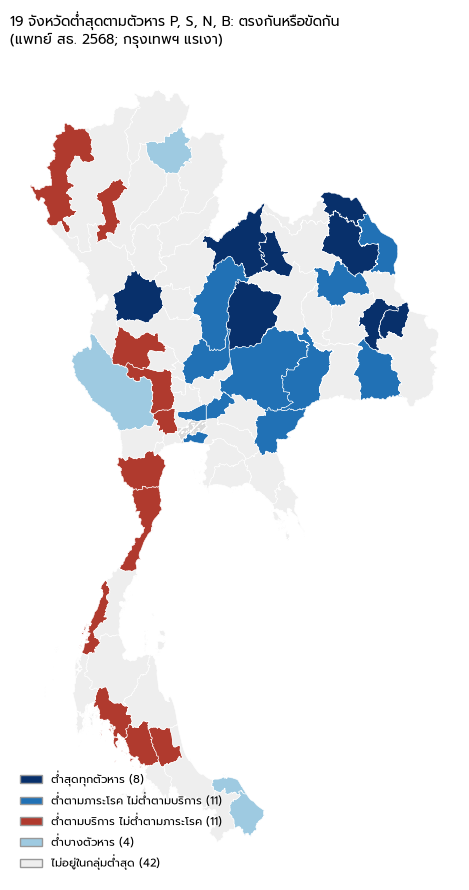

In [8]:
import geopandas as gpd
geo = gpd.read_file(C.ROOT / "output/map/geo_prov.geojson").rename(columns={"prov_id": "prov_code"})
geo["prov_code"] = geo.prov_code.astype(int)
geo = geo.merge(G[["prov_code", "group"]], on="prov_code", how="left")
GROUP_TH = {"all_four": "ต่ำสุดทุกตัวหาร", "need_not_service": "ต่ำตามภาระโรค ไม่ต่ำตามบริการ",
            "service_not_need": "ต่ำตามบริการ ไม่ต่ำตามภาระโรค", "mixed": "ต่ำบางตัวหาร", "none": "ไม่อยู่ในกลุ่มต่ำสุด"}
GROUP_COL = {"all_four": "#08306b", "need_not_service": "#2171b5", "service_not_need": "#b03a2e", "mixed": "#9ecae1", "none": "#eeeeee"}
fig, ax = plt.subplots(figsize=(6.5, 9))
for g_, col in GROUP_COL.items():
    z = geo[geo.group == g_]
    if len(z):
        z.plot(ax=ax, color=col, edgecolor="white", linewidth=0.4, label=f"{GROUP_TH[g_]} ({len(z)})")
geo[geo.prov_code == BK].plot(ax=ax, color="#d9d9d9", edgecolor="white", linewidth=0.4, hatch="///")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=c, edgecolor="#999", label=f"{GROUP_TH[g]} ({int((G.group == g).sum())})") for g, c in GROUP_COL.items()],
          loc="lower left", frameon=False, fontsize=8)
ax.set_axis_off()
ax.set_title("19 จังหวัดต่ำสุดตามตัวหาร P, S, N, B: ตรงกันหรือขัดกัน\n(แพทย์ สธ. 2568; กรุงเทพฯ แรเงา)", fontsize=10, loc="left")
fig.tight_layout()
S.figure("F46_RANK_DISAGREEMENT_MAP", fig, G, "แผนที่ความตรงกันและความขัดกันของรายชื่อ 19 จังหวัดต่ำสุดตามตัวหารประชากร บริการ ความจำเป็น M5 และภาระโรค (แพทย์ สธ. 2568)", main=True)
plt.show()

---
# ส่วน D — ความน่าเชื่อถือของตัวชี้วัดในบทที่ 4
สรุปจากตารางผลเดิมของ 4.2.3 และ 4.5 (ข้ามจังหวัด ข้ามเวลา ภาระโรค) ด้วยฟังก์ชันเดียวกับบัญชีการตรวจสอบของบทที่ 5

In [9]:
from chapter5 import config as C5cfg, validation as VAL
inv4 = VAL.inventory(C5cfg.load(), chapter4_only=True)
S.table("T46_VALIDATION_SUMMARY", VAL.summary_th(inv4), "สรุปความน่าเชื่อถือของแบบจำลองบริการในบทที่ 4: ตัวเทียบ ระยะ ผล และข้อจำกัด")
S.claim("c46_val_n", len(inv4), "int", "รายการ")
S.claim("c46_val_temporal_fail", int(((inv4.evidence_type.str.startswith("temporal")) & (inv4.verdict == "does_not_beat_comparator")).sum()), "int", "รายการ")
S.claim("c46_val_temporal_n", int(inv4.evidence_type.str.startswith("temporal").sum()), "int", "รายการ")
display(VAL.summary_th(inv4))

,รหัส,องค์ประกอบ,ชนิดหลักฐาน,ตัวเทียบ,ตัวชี้วัด,แบบจำลอง,ตัวเทียบ (ค่า),ผล,ข้อจำกัด
0,C4-CV-op_moph,service model M5 (op_moph),spatial: repeated 5-fold province-grouped CV,M0 (year effects only),R² vs training-fold mean,0.462,0.182,ดีกว่าตัวเทียบ,"prediction across provinces, not through time;..."
1,C4-CV-ip_moph,service model M5 (ip_moph),spatial: repeated 5-fold province-grouped CV,M0 (year effects only),R² vs training-fold mean,0.592,0.245,ดีกว่าตัวเทียบ,"prediction across provinces, not through time;..."
2,C4-CV-adjrw,service model M5 (adjrw),spatial: repeated 5-fold province-grouped CV,M0 (year effects only),R² vs training-fold mean,0.511,0.0729,ดีกว่าตัวเทียบ,"prediction across provinces, not through time;..."
3,C4-TEMP-op_moph-2024,service model M5 (op_moph),temporal holdout (one year ahead),persistence (last observed rate),R² vs training mean,0.599,0.829,ไม่ดีกว่าตัวเทียบ,short series (2022 onwards); explanatory fit i...
4,C4-TEMP-op_moph-2025,service model M5 (op_moph),temporal holdout (one year ahead),persistence (last observed rate),R² vs training mean,0.381,0.673,ไม่ดีกว่าตัวเทียบ,short series (2022 onwards); explanatory fit i...
5,C4-TEMP-ip_moph-2024,service model M5 (ip_moph),temporal holdout (one year ahead),persistence (last observed rate),R² vs training mean,0.441,0.889,ไม่ดีกว่าตัวเทียบ,short series (2022 onwards); explanatory fit i...
6,C4-TEMP-ip_moph-2025,service model M5 (ip_moph),temporal holdout (one year ahead),persistence (last observed rate),R² vs training mean,0.36,0.804,ไม่ดีกว่าตัวเทียบ,short series (2022 onwards); explanatory fit i...
7,C4-TEMP-adjrw-2024,service model M5 (adjrw),temporal holdout (one year ahead),persistence (last observed rate),R² vs training mean,0.63,0.883,ไม่ดีกว่าตัวเทียบ,short series (2022 onwards); explanatory fit i...
8,C4-TEMP-adjrw-2025,service model M5 (adjrw),temporal holdout (one year ahead),persistence (last observed rate),R² vs training mean,0.695,0.946,ไม่ดีกว่าตัวเทียบ,short series (2022 onwards); explanatory fit i...
9,C45-CV-op_moph,BOD burden as service predictor (op_moph),spatial: paired province-grouped CV,M1 (age only),% SSE reduction (95% cluster bootstrap),-5.76,0,ไม่ดีกว่าตัวเทียบ,tests prediction of recorded hospital activity...


In [10]:
manifest = S.finalize(extra_manifest=dict(spc_window=SPC_YEARS))
print({k: manifest[k] for k in ["n_tables", "n_figures", "n_claims", "seconds"]})

{'n_tables': 9, 'n_figures': 3, 'n_claims': 74, 'seconds': 3.9}
